In [12]:
import numpy as np
import matplotlib.pyplot as plt
import gudhi

In [26]:
num_files = 15
num_points = 51
num_steps = 50000
steps = np.empty((num_files, num_points), dtype=np.float32)
us = np.empty((num_files, num_points, 256, 256), dtype=np.float32)
vs = np.empty((num_files, num_points, 256, 256), dtype=np.float32)

idx = 0
chi_values = np.round(np.linspace(4.00, 4.30, 15), decimals=2)
for i in chi_values:
    filepath = "C:/Users/zekem/Documents/keller-segel-phase-transitions/data/runs/keller_segel_logistic/sensitivity_sweep/chi="+str(i)+"_steps="+str(num_steps)+".npz"
    with np.load(filepath, allow_pickle=True) as data:
        steps[idx] = data['step']
        us[idx] = data['u']
        vs[idx] = data['v']
    idx += 1

print(steps.shape, us.shape, vs.shape)

(15, 51) (15, 51, 256, 256) (15, 51, 256, 256)


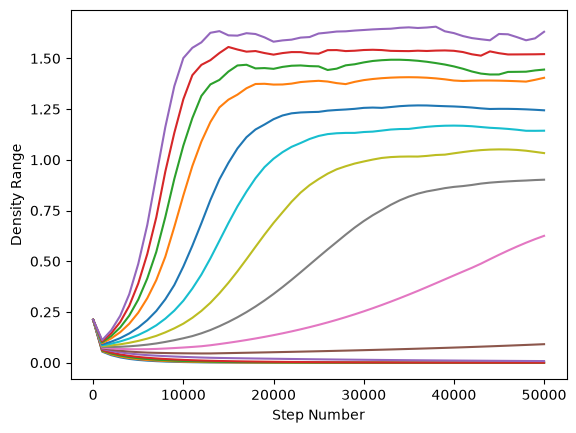

In [29]:
for i in range(num_files):
    x = np.linspace(0, 50000, num_points)
    density_range = np.empty((steps[i].shape))
    for j in range(len(steps[i])):
        density_range[j] = np.max(us[i, j]) - np.min(us[i, j])
    #plt.ylim(0.025, 0.2)
    plt.xlabel("Step Number")
    plt.ylabel("Density Range")
    plt.plot(x, density_range, label="Chi="+str(chi_values[i]))

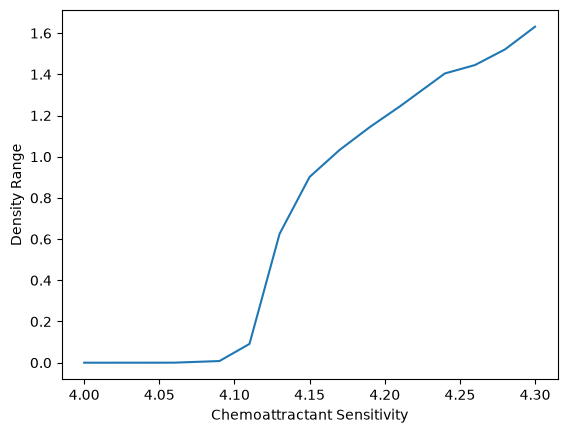

In [36]:
for i in range(num_files):
    x = chi_values
    max_density_range = np.empty((num_files))
    max_density_range[i] = np.max(us[i, num_points-1]) - np.min(us[i, num_points-1])
plt.xlabel("Chemoattractant Sensitivity")
plt.ylabel("Density Range")
plt.plot(x, max_density_range)

# Constants and Initial Conditions:
* DT = 0.1
* N = 512
* DU = 0.2
* DV = 1
* SATURATION = 0.1
* ALPHA = 0.1
* BETA = 1
* CAPACITY = 2
* densities = np.ones((N, N))
* densities += np.random.uniform(-0.1, 0.1, (N, N))
* chemoattractant = np.ones((N, N))
* chemoattractant += np.random.uniform(-0.1, 0.1, (N, N))
# Stable Endpoints:
* For SENSITIVITY in range approximately 0 - 4.1, the chemotaxis term does not overcome the diffusion of cells, resulting in a flat, evenly diffused plane of density.
* For SENSITIVITY between 4.1 and 5.6, the chemotaxis term overcome the diffusion, resulting in a network of dense nodes connected by medium-density edges. Due to the logistic growth term, the nodes reach a high density before stopping growing. Edges take in the chemoattractant from between them, leaving gaps of near-zero density. Due to these processes, the network stops moving once it becomes sufficiently concentrated.
* For SENSITIVITY at or above 5.6, the density field follows dynamics similar to those of the previous SENSITIVITY range, but density eventually grows too high, causing the system to blow up from the explicit computation of the chemotaxis term. This explicit computation is practically unavoidable due to the nonlinearity of the term, meaning the simulation cannot be meaningfully tested at higher SENSITIVITY.